t‑SNE: нелинейное вложение, оптимизирует дивергенцию Кульбака–Лейблера между распределениями близостей точек, хорошо показывает локальные кластеры, но медленно, плохо сохраняет глобальные расстояния, чувствительно к perplexity и random_state.

UMAP: основан на теории многобразий и топологии, строит взвешенный граф соседей и оптимизирует кросс‑энтропию; быстрее t‑SNE, лучше сохраняет глобальную структуру, более устойчив к малым изменениям параметров (n_neighbors, min_dist).

TriMAP: ориентирован на сохранение глобальной структуры через тройки точек (anchor, сосед, далёкий), улучшает глобальное расположение кластеров при сохранении локальной структуры.

PaCMAP: управляет соотношением близких, средних и далёких пар, чтобы одновременно хорошо держать локальные кластеры и общую форму; показывает хорошие результаты на омикс‑данных и эмбеддингах.

PHATE: использует диффузионные процессы и потенциал для визуализации непрерывных траекторий (например, дифференцировка клеток), хорошо показывает как кластеры, так и переходы между ними.



In [1]:
%pip install umap-learn trimap pacmap phate scikit-learn seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 9.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 25.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 46.1 MB/s  0:00:00
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520037 sha256=054dc9f4359650f5af18a73759a53bcb80ce2f1282340cb7d6d810eb48595664
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [phate]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

from sklearn.manifold import TSNE
import umap
import trimap
import pacmap
import phate



In [3]:
iris = load_iris()
X_iris = iris.data
y_iris = iris.target
feature_names_iris = iris.feature_names
print(X_iris.shape, np.unique(y_iris))


(150, 4) [0 1 2]


In [4]:
path = "/content/ObesityDataSet.csv"  # замените на свой путь
df = pd.read_csv(path)
df.head()


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

def _keep_top_classes(df: pd.DataFrame, target_col: str, n_classes: int) -> pd.DataFrame:
    """Топ n самых частых классов в датасете"""
    uniq = df[target_col].nunique()
    if n_classes >= uniq:
        return df

    top = df[target_col].value_counts().head(n_classes).index
    trimmed = df[df[target_col].isin(top)]
    return trimmed

def _make_preprocessor(numeric_cols: list[str], cat_cols: list[str]) -> ColumnTransformer:
    """Преобразование числовых и категориальных признаков."""
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_cols),
            ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
        ]
    )

# Оставляем нужное число классов (7 — весь датасет, или поставьте 4 для быстрого расчёта)
n_classes = 7
df_filtered = _keep_top_classes(df, target_col="NObeyesdad", n_classes=n_classes)

numeric_cols = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
cat_cols = ["Gender", "family_history_with_overweight", "FAVC", "CAEC", "SMOKE", "SCC", "CALC", "MTRANS"]

preprocessor = _make_preprocessor(numeric_cols, cat_cols)
X_own = preprocessor.fit_transform(df_filtered.drop(columns=["NObeyesdad"]))

le = LabelEncoder()
y_own = le.fit_transform(df_filtered["NObeyesdad"])
class_names_own = le.classes_

print("Obesity:", X_own.shape, len(np.unique(y_own)))


Obesity: (2111, 23) 7


In [7]:
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)



Функции для DR и оценки разделения

In [13]:
from sklearn.manifold import TSNE
import umap
import trimap
import pacmap
import phate

def run_tsne(X, random_state=42, perplexity=30, learning_rate=200, n_iter=1000):
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        learning_rate=learning_rate,
        max_iter=n_iter,
        random_state=random_state
    )
    return tsne.fit_transform(X)

def run_umap(X, random_state=42, n_neighbors=15, min_dist=0.1):
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        random_state=random_state
    )
    return reducer.fit_transform(X)

def run_trimap(X, random_state=42, n_inliers=10, n_outliers=5):
    reducer = trimap.TRIMAP(
        n_dims=2,
        n_inliers=n_inliers,
        n_outliers=n_outliers
    )
    return reducer.fit_transform(X)

def run_pacmap(X, random_state=42, n_neighbors=10):
    reducer = pacmap.PaCMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        random_state=random_state
    )
    return reducer.fit_transform(X)

def run_phate(X, random_state=42, knn=15):
    phate_op = phate.PHATE(
        n_components=2,
        knn=knn,
        random_state=random_state,
        verbose=False
    )
    return phate_op.fit_transform(X)


Функция оценки качества разделения

In [14]:
def separation_score(X_2d, y):
    D = pairwise_distances(X_2d)
    same = D[y[:, None] == y[None, :]]
    diff = D[y[:, None] != y[None, :]]
    return same.mean(), diff.mean(), diff.mean() / same.mean()


In [15]:
# Отрисовка

def plot_embedding(X_2d, y, title):
    plt.figure(figsize=(6, 5))
    sns.scatterplot(
        x=X_2d[:, 0],
        y=X_2d[:, 1],
        hue=y,
        palette="tab10",
        s=30,
        legend="full"
    )
    plt.title(title)
    plt.xticks([])
    plt.yticks([])
    plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


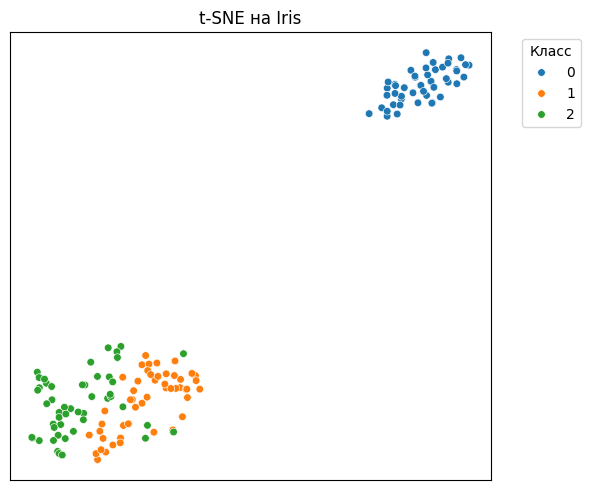

t-SNE: внутрикласс.=3.512, межкласс.=22.740, ratio=6.475


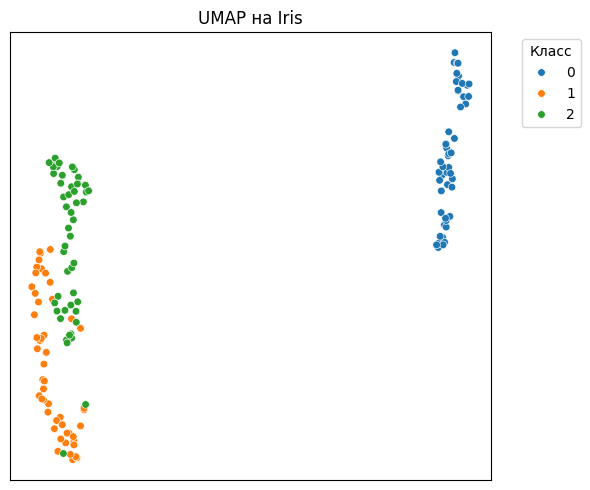

UMAP: внутрикласс.=1.836, межкласс.=14.357, ratio=7.818


In [16]:
X_list = []
names = []

X_tsne_iris = run_tsne(X_iris_scaled, random_state=42)
X_list.append(X_tsne_iris); names.append("t-SNE")

X_umap_iris = run_umap(X_iris_scaled, random_state=42)
X_list.append(X_umap_iris); names.append("UMAP")

"TriMAP"

"PaCMAP"

"PHATE"

for X_emb, name in zip(X_list, names):
    plot_embedding(X_emb, y_iris, f"{name} на Iris")
    same, diff, ratio = separation_score(X_emb, y_iris)
    print(
        f"{name}: внутрикласс.={same:.3f}, межкласс.={diff:.3f}, ratio={ratio:.3f}"
    )


Сравнение устойчивости

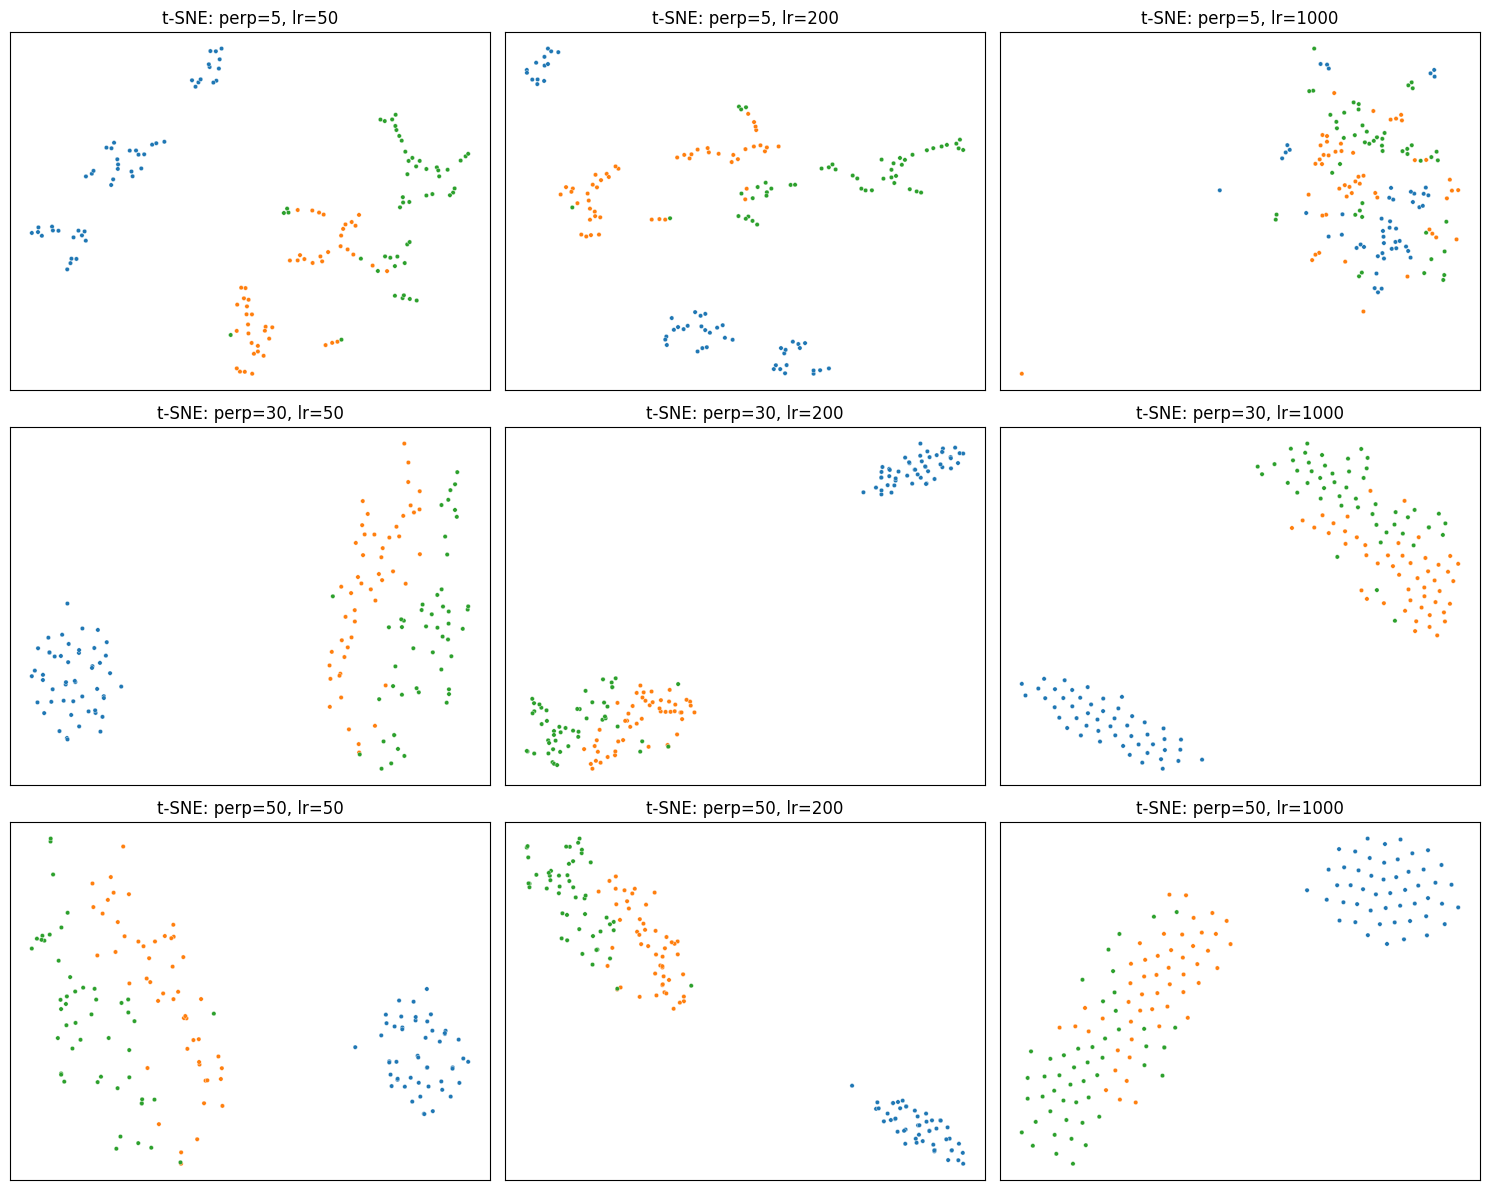

In [17]:
perplexities = [5, 30, 50]
lrs = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(lrs), figsize=(5*len(lrs), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(lrs):
        X_emb = run_tsne(X_iris_scaled, random_state=42, perplexity=perp, learning_rate=lr)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1], hue=y_iris, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"t-SNE: perp={perp}, lr={lr}")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()


Нужно описать, как меняется форма и расположение кластеров при разных perplexity и learning_rate и что визуализация t‑SNE может сильно меняться.

e:\fmi-ml-courses\clusters\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
e:\fmi-ml-courses\clusters\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
e:\fmi-ml-courses\clusters\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
e:\fmi-ml-courses\clusters\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
e:\fmi-ml-courses\clusters\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
e:\fmi-ml-courses\clusters\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 

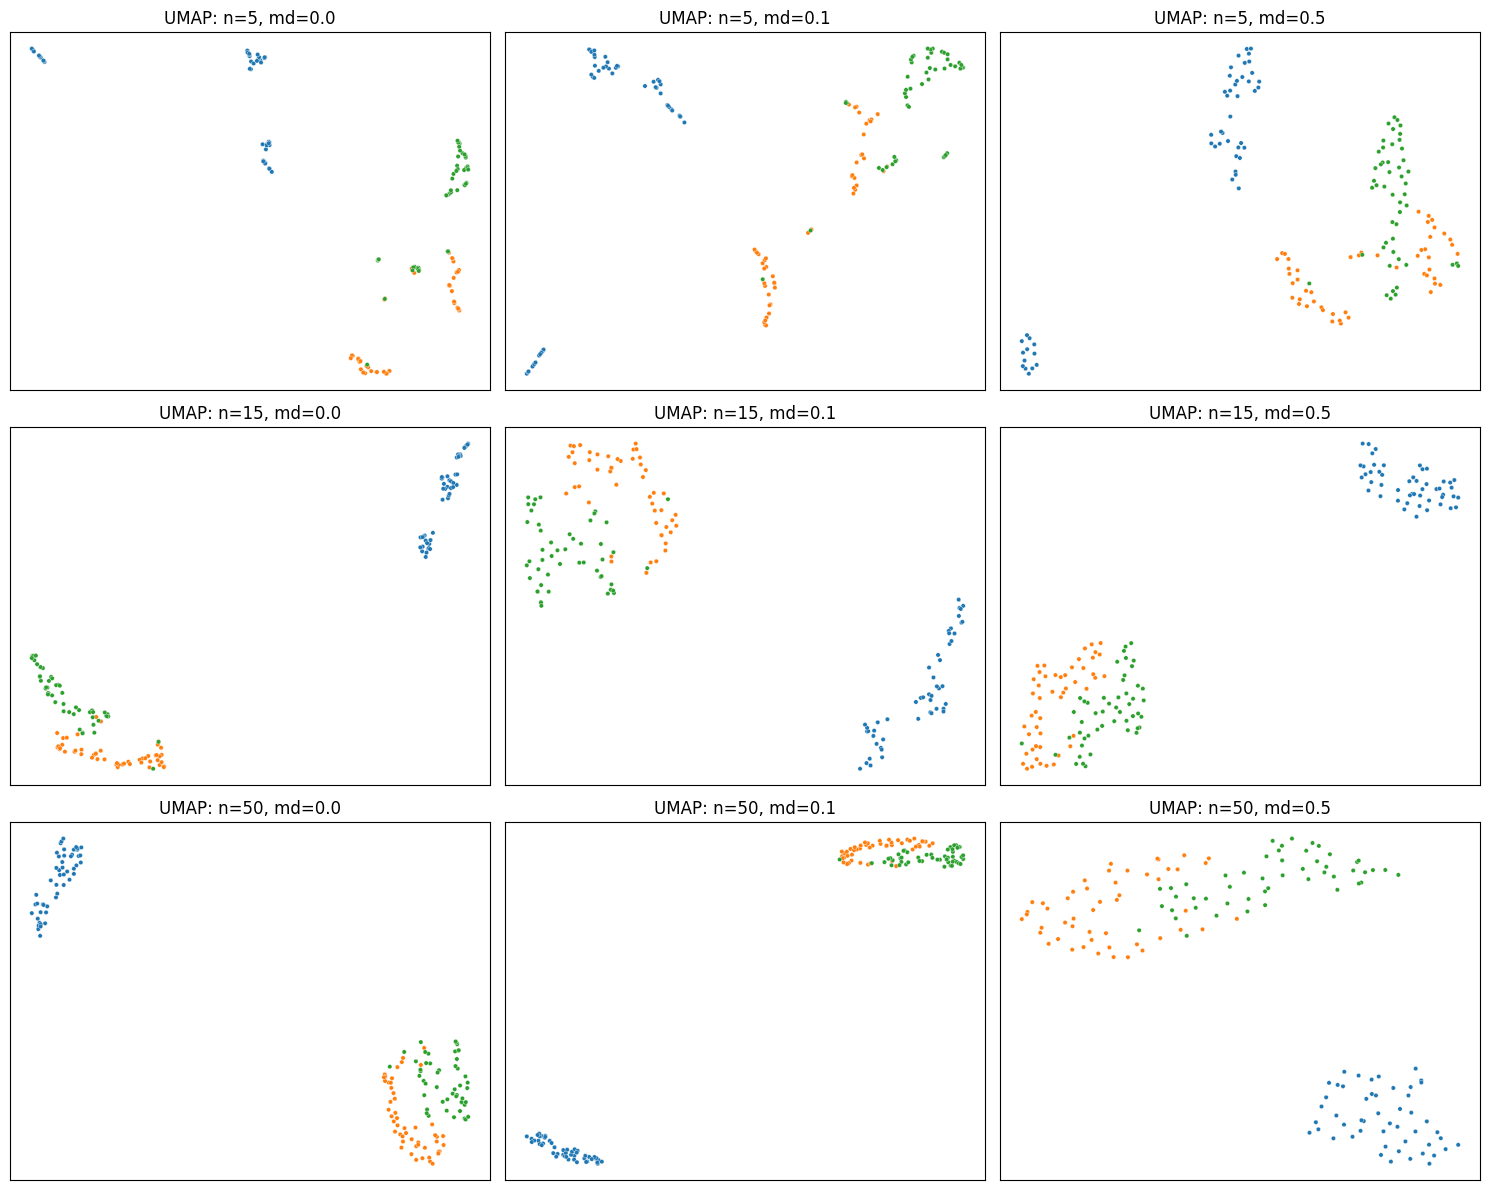

In [ ]:
"UMAP....

Обычно структура UMAP меняется плавнее, кластеры остаются узнаваемыми при разумном диапазоне параметров.

*Задача* Аналогично нужно сделать по одной строке графиков для TriMAP, PaCMAP, PHATE с варьированием ключевого параметра (количество соседей или похожий гиперпараметр) и показать, насколько устойчив рисунок.



| Метод  | Скорость на больших данных                   | Локальное разделение              | Глобальная структура                            | Чувствительность к параметрам                         | Комментарий                                        |
| ------ | -------------------------------------------- | --------------------------------- | ----------------------------------------------- | ----------------------------------------------------- | -------------------------------------------------- |
| t‑SNE  | Низкая l                    | Отличное                   | Слабая                                   | Высокая (perplexity, lr, random_state) aicompetence+2 | Хорошо для локальных кластеров, тяжёлый тюнинг     |
| UMAP   | Высокая l                   | Очень хорошее   | Лучшая, чем у t‑SNE           | Ниже, чем у t‑SNE aicompetence+2                      | Хороший баланс локал/глобал, удобен в практике     |
| TriMAP | Средняя                              | Хорошее                   | Сильный упор на глобальную структуру    | Умеренная                                     | Лучше показывает относительное положение кластеров |
| PaCMAP | Средняя                               | Отличное                   | Хорошее                                  | Умеренная                                      | Часто даёт чёткие кластеры и форму многобразия     |
| PHATE  | Средняя/низкая (зависит от размера)   | Хорошее        | Очень хорошее, особенно для траекторий   | Умеренная                          | Сильный метод для непрерывных переходов            |

# Варианты препроцессинга
*Задача* — явно сравнить, как UMAP и t‑SNE реагируют на разные варианты нормировки и отбора признаков.

## Определяем три сценария
Без масштабирования (сырой набор признаков).

StandardScaler (z‑нормировка).

MinMaxScaler + отбор признаков по дисперсии (эмуляция feature selection).

Задание. Проделать все три сценария. Обучить все модели при разных сценария кластеризации.
Нужно в результате:
1. описать, какие признаки были отброшены и почему это может влиять на качество кластеризации во вложенном пространстве.
1. сравнить вычислительное время и сделать вывод о масштабируемости методов
1. изменить гиперпараметры (perplexity, n_neighbors, min_dist) и исследовать совместное влияние гиперпараметров и препроцессинга на структуру кластеров.


/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:810: RuntimeWarning: Detected zero distance between 118 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:505: RuntimeWarning: divide by zero encountered in divide
  scaled = distances_i / bw
/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:505: RuntimeWarning: invalid value encountered in divide
  scaled = distances_i / bw
/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:540: RuntimeWarning: invalid value encountered in divide
  scaled = distances_i / bw


    SGD-MDS may not have converged: stress changed by -1.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.


/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:810: RuntimeWarning: Detected zero distance between 118 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:810: RuntimeWarning: Detected zero distance between 118 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


    SGD-MDS may not have converged: stress changed by 3.2% in final iterations. Consider increasing n_iter or adjusting learning_rate.


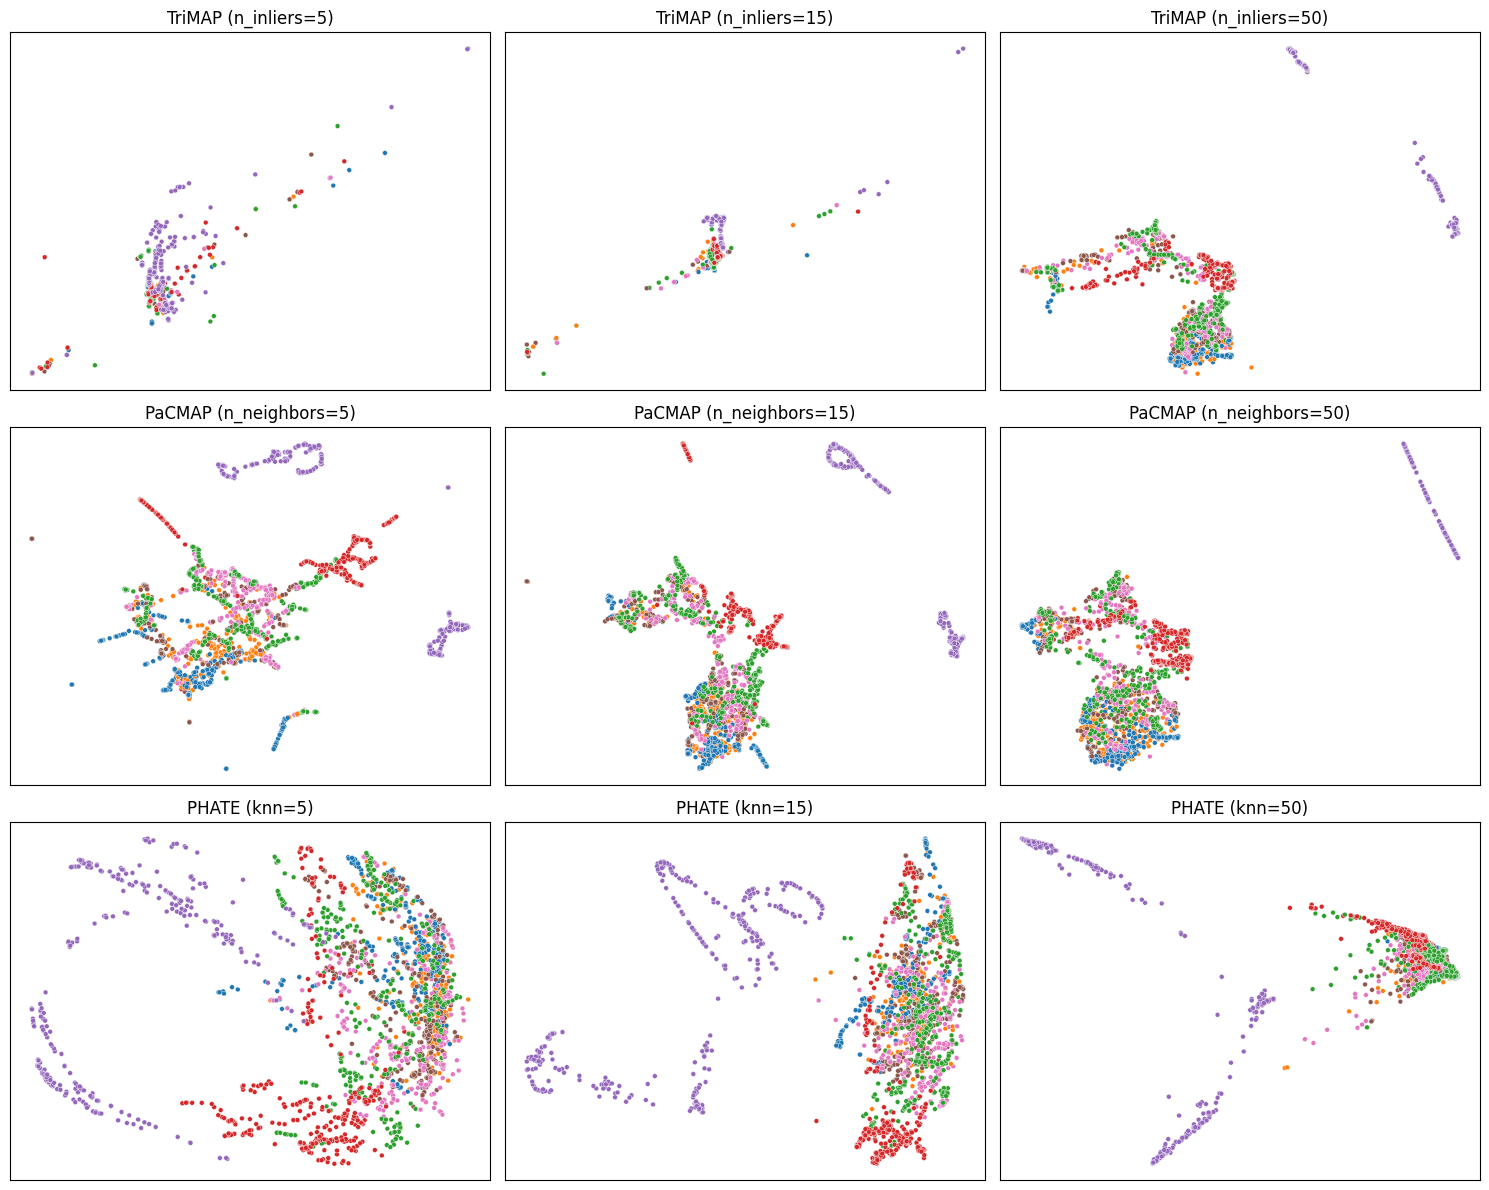

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

# 1. Гарантированно пересоздаем числовую матрицу X_own и метки y_own
numeric_cols = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
cat_cols = ["Gender", "family_history_with_overweight", "FAVC", "CAEC", "SMOKE", "SCC", "CALC", "MTRANS"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
    ]
)

X_own = preprocessor.fit_transform(df.drop(columns=["NObeyesdad"]))
y_own = LabelEncoder().fit_transform(df["NObeyesdad"])

# 2. Строим графики для TriMAP, PaCMAP и PHATE
neighbors_list = list((5, 15, 50))
fig, axes = plt.subplots(3, len(neighbors_list), figsize=(15, 12))

# TriMAP (варьируем n_inliers)
for j, k in enumerate(neighbors_list):
    emb = run_trimap(X_own, n_inliers=k, n_outliers=max(2, k // 2))
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y_own, palette="tab10", s=12, ax=axes[0, j], legend=False)
    axes[0, j].set_title(f"TriMAP (n_inliers={k})")
    axes[0, j].set_xticks([]); axes[0, j].set_yticks([])

# PaCMAP (варьируем n_neighbors)
for j, k in enumerate(neighbors_list):
    emb = run_pacmap(X_own, n_neighbors=k)
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y_own, palette="tab10", s=12, ax=axes[1, j], legend=False)
    axes[1, j].set_title(f"PaCMAP (n_neighbors={k})")
    axes[1, j].set_xticks([]); axes[1, j].set_yticks([])

# PHATE (варьируем knn)
for j, k in enumerate(neighbors_list):
    emb = run_phate(X_own, knn=k)
    sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y_own, palette="tab10", s=12, ax=axes[2, j], legend=False)
    axes[2, j].set_title(f"PHATE (knn={k})")
    axes[2, j].set_xticks([]); axes[2, j].set_yticks([])

plt.tight_layout()
plt.show()


In [21]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.feature_selection import VarianceThreshold

numeric_cols = list(("Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"))
cat_cols = list(("Gender", "family_history_with_overweight", "FAVC", "CAEC", "SMOKE", "SCC", "CALC", "MTRANS"))

X_df_raw = df.drop(columns=list(("NObeyesdad",)))
y_own = LabelEncoder().fit_transform(df["NObeyesdad"])

prep_raw = ColumnTransformer(list((
    ("num", "passthrough", numeric_cols),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols)
)))
X_scen1_raw = prep_raw.fit_transform(X_df_raw)
all_feature_names = numeric_cols + list(prep_raw.named_transformers_["cat"].get_feature_names_out(cat_cols))

prep_std = ColumnTransformer(list((
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols)
)))
X_scen2_std = prep_std.fit_transform(X_df_raw)

prep_minmax = ColumnTransformer(list((
    ("num", MinMaxScaler(), numeric_cols),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols)
)))
X_minmax_full = prep_minmax.fit_transform(X_df_raw)

selector = VarianceThreshold(threshold=0.05)
X_scen3_var = selector.fit_transform(X_minmax_full)

kept_mask = selector.get_support()
dropped_features = [name for name, kept in zip(all_feature_names, kept_mask) if not kept]

print(f"Было признаков: {len(all_feature_names)}, осталось после отбора: {X_scen3_var.shape[1]}")
print("Отброшенные признаки (дисперсия < 0.05):")
for feat in dropped_features:
    print(" -", feat)


Было признаков: 23, осталось после отбора: 13
Отброшенные признаки (дисперсия < 0.05):
 - Age
 - Height
 - Weight
 - CAEC_no
 - SMOKE_yes
 - SCC_yes
 - CALC_Frequently
 - MTRANS_Bike
 - MTRANS_Motorbike
 - MTRANS_Walking


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:810: RuntimeWarning: Detected zero distance between 118 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/graphtools/graphs.py:810: RuntimeWarning: Detected zero distance between 118 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/graphtools/graph

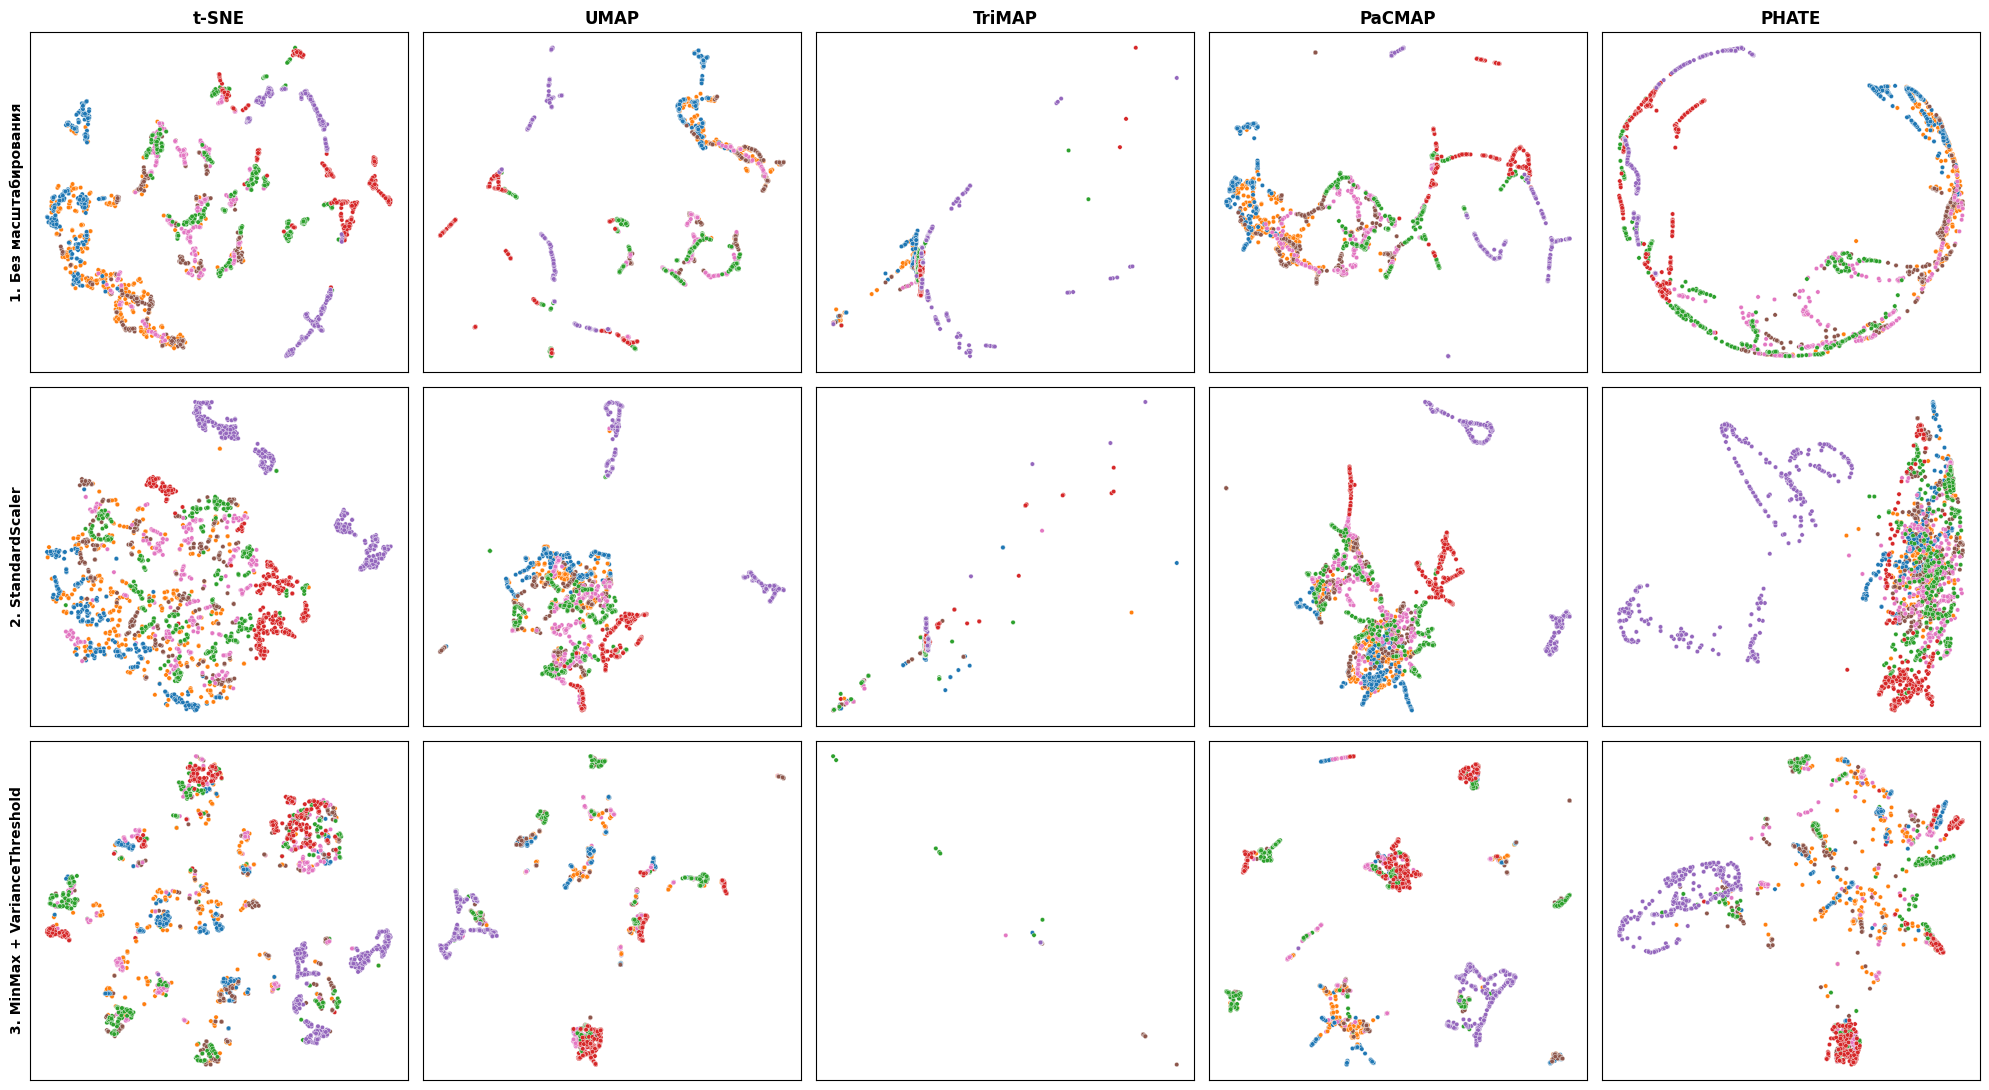

Сценарий,1. Без масштабирования,2. StandardScaler,3. MinMax + VarianceThreshold
Метод,,,
PHATE,15.518,16.533,15.904
PaCMAP,1.614,1.288,0.966
TriMAP,2.816,3.890,3.848
UMAP,16.419,9.026,8.261
t-SNE,40.790,17.556,18.921


In [22]:
scenarios = {
    "1. Без масштабирования": X_scen1_raw,
    "2. StandardScaler": X_scen2_std,
    "3. MinMax + VarianceThreshold": X_scen3_var
}

methods = {
    "t-SNE": lambda X: run_tsne(X, perplexity=30),
    "UMAP": lambda X: run_umap(X, n_neighbors=15, min_dist=0.1),
    "TriMAP": lambda X: run_trimap(X, n_inliers=10),
    "PaCMAP": lambda X: run_pacmap(X, n_neighbors=10),
    "PHATE": lambda X: run_phate(X, knn=15)
}

time_records = list()
fig, axes = plt.subplots(len(scenarios), len(methods), figsize=(20, 11))

for i, (scen_name, X_data) in enumerate(scenarios.items()):
    for j, (meth_name, func) in enumerate(methods.items()):
        t0 = time.perf_counter()
        emb = func(X_data)
        elapsed = time.perf_counter() - t0
        time_records.append({"Сценарий": scen_name, "Метод": meth_name, "Время (сек)": round(elapsed, 3)})

        ax = axes[i, j]
        sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y_own, palette="tab10", s=10, ax=ax, legend=False)
        if i == 0:
            ax.set_title(meth_name, fontsize=12, fontweight="bold")
        if j == 0:
            ax.set_ylabel(scen_name, fontsize=10, fontweight="bold")
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

df_times = pd.DataFrame(time_records).pivot(index="Метод", columns="Сценарий", values="Время (сек)")
display(df_times)
